In [1]:
import numpy as np
import pandas as pd
# data visualization
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import style

# Partie 1 — Explorer et vérifier les données

### 1 Chargez le fichier CSV avec pandas. Affichez les cinq premières lignes, le nombre de lignes et de colonnes, ainsi que les types de variables.

In [2]:
data = pd.read_csv('transactions_TP2.csv')    

In [3]:
print(data.head())

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [4]:
print(data.shape)

(3045, 12)


In [5]:
print(data.dtypes)

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


### 2 Calculez, pour chaque colonne, le nombre et le pourcentage de valeurs manquantes. Présentez le résultat dans un tableau trié du plus grand au plus petit pourcentage.

In [6]:

# 1. Calcul du nombre de valeurs manquantes
manquante_count = data.isnull().sum()

# 2. Calcul du pourcentage de valeurs manquantes
manquante_percent = ((data.isnull().sum() / len(data)) * 100).round(2)

# 3. Combinaison dans un nouveau DataFrame
manquante_table = pd.DataFrame(
    {"Valeurs Manquantes": manquante_count, "Pourcentage (%)": manquante_percent}
)

# 4. Tri du plus grand au plus petit pourcentage
manquante_table_sorted = manquante_table.sort_values(
    by="Pourcentage (%)", ascending=False
)

# Affichage du résultat
print(manquante_table_sorted )


                  Valeurs Manquantes  Pourcentage (%)
canal                            159             5.22
anciennete_mois                  137             4.50
appareil                         122             4.01
montant_dh                       110             3.61
region                           103             3.38
nb_ops_24h                        53             1.74
id_operation                       0             0.00
id_client                          0             0.00
heure                              0             0.00
international                      0             0.00
resultat_enquete                   0             0.00
fraude                             0             0.00


### 3 Recherchez les opérations répétées avec id_operation. Combien de doublons trouvez-vous ? Supprimez-les et indiquez le nombre de lignes restantes.

In [7]:
# 1. Compter le nombre de doublons basés sur 'id_operation'
nb_doublons = data.duplicated(subset=['id_operation']).sum()
print(f"Nombre de doublons trouvés : {nb_doublons}")

# 2. Supprimer les doublons et garder la première occurrence
data_nettoye = data.drop_duplicates(subset=['id_operation'], keep='first')

# 3. Compter les lignes restantes
lignes_restantes = len(data_nettoye)
print(f"Nombre de lignes restantes : {lignes_restantes}")

Nombre de doublons trouvés : 45
Nombre de lignes restantes : 3000


### 4 Tracez un histogramme du montant et un boxplot. Repérez quelques montants extrêmes. Faut-il forcément les supprimer ? Justifiez votre réponse.

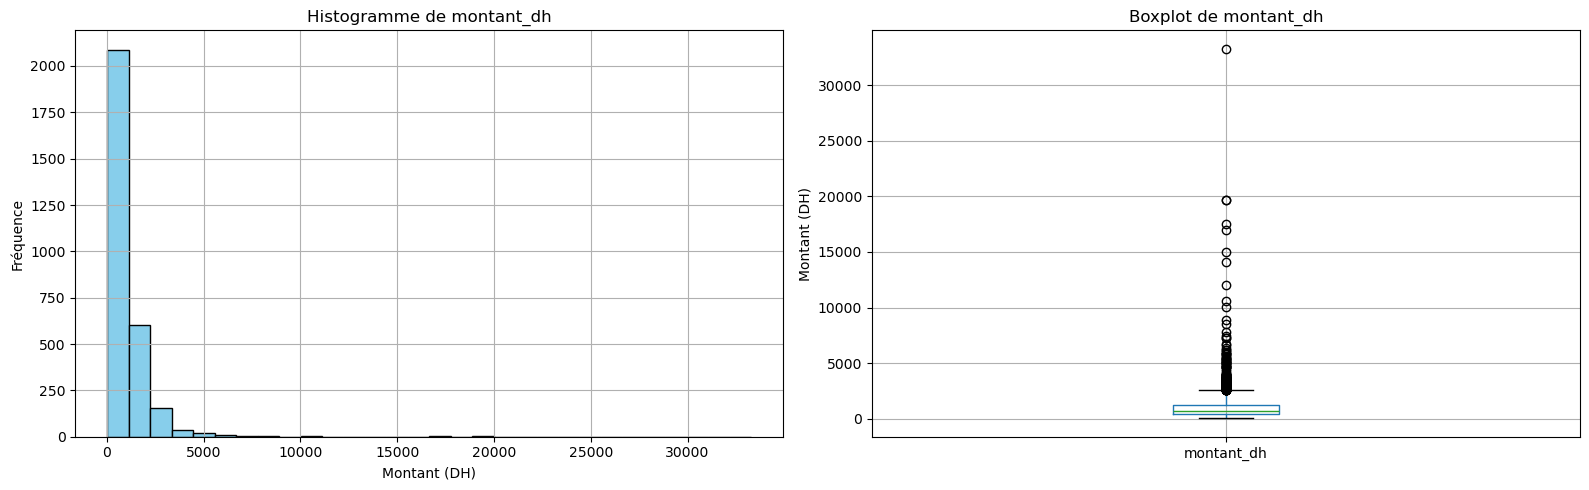

In [8]:


# Création de la figure avec 2 graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Histogramme 
data["montant_dh"].hist(bins=30, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title("Histogramme de montant_dh")
axes[0].set_xlabel("Montant (DH)")
axes[0].set_ylabel("Fréquence")

# 2. Boxplot 
data.boxplot(column="montant_dh", ax=axes[1])
axes[1].set_title("Boxplot de montant_dh")
axes[1].set_ylabel("Montant (DH)")

plt.tight_layout()#ajuste automatiquement l'espacement.
plt.show()

## Une valeur extrême n'est pas toujours une erreur. Elle peut correspondre à une situation réelle et significative. Il est donc important de vérifier d'où elle vient avant de décider de la supprimer. 
#### exemple:
#### -Un client effectue, de manière exceptionnelle, une transaction de 33 000 DH. Cette opération peut parfaitement être réelle et légitime.

#### 5 -Calculez la proportion de fraudes (fraude = 1) et tracez un diagramme des deux classes. Le fichier est-il équilibré ? Pourquoi est-ce important pour préparer les données ?

In [10]:
# Q5 : Calcul de la proportion de fraudes
proportion_fraude = (data['fraude'] == 1).mean() *100
print(f"La proportion de fraudes est de : {proportion_fraude:.2f}%")

La proportion de fraudes est de : 8.67%


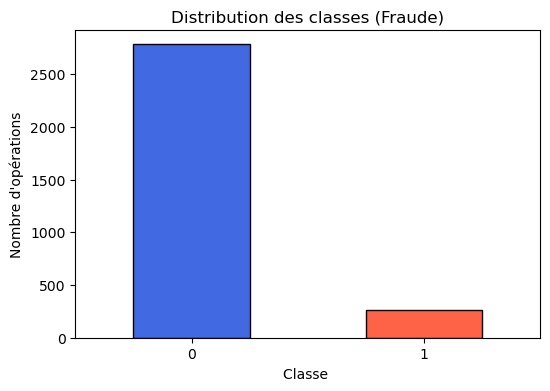

In [12]:
# 2. Visualisation du diagramme des deux classes
plt.figure(figsize=(6, 4))
data['fraude'].value_counts().plot(kind='bar', color=['royalblue', 'tomato'], edgecolor='black')
plt.title('Distribution des classes (Fraude)')
plt.xlabel('Classe ')
plt.ylabel("Nombre d'opérations")
plt.xticks(rotation=0)
plt.show()

### D apres le calcule de proportion et distribution des classe ona fraude = 1 de porcentage 8.67% et alore que la porcentage de  fraude = 0 et constituent la grande majorité avec 91.33% ce qui montre que Le fichier  n'est pas équilibré.Je constate d aprait cette déséquilibre que  le modèle de Machine Learning peut se concentrer uniquement sur la classe majoritaire (fraud =0 ) et et néglige (fraud =1)


#### 6- Repérez les identifiants et la colonne resultat_enquete. Expliquez pourquoi ces colonnes ne doivent pas être incluses dans les variables préparées. À quel moment connait-on resultat_enquete ?

In [15]:
# Colonnes à exclure des variables préparées
colonnes_exclues = ['id_operation', 'id_client', 'resultat_enquete']

# Affichage des colonnes concernées
print("Colonnes identifiées :")
print(data[colonnes_exclues].head())

# Vérification de ce que contient resultat_enquete
print("\nValeurs uniques de resultat_enquete :")
print(data['resultat_enquete'].value_counts(dropna=False))

Colonnes identifiées :
  id_operation id_client resultat_enquete
0      OP02438    C10278    aucune_fraude
1      OP00157    C10019    aucune_fraude
2      OP01987    C10604    aucune_fraude
3      OP00207    C10330    aucune_fraude
4      OP00738    C10380    aucune_fraude

Valeurs uniques de resultat_enquete :
resultat_enquete
aucune_fraude       2781
fraude_confirmee     264
Name: count, dtype: int64


### Les identifiants et la colonne resultat_enquete doivent être exclus des variables explicatives car ils n'apportent aucune valeur prédictive en temps réel. Les conserver risquerait d'entraîner respectivement un surapprentissage (overfitting) et une fuite de données (data leakage), le système devant détecter la fraude avant toute investigation.

# Partie 2 — Préparer les données sans fuite

#### 7-Après suppression des doublons, créez X (variables à préparer) et y (fraude). Retirez de X les identifiants et resultat_enquete. Conservez y pour étudier le déséquilibre des classes.

In [19]:
# 1. Supprimer les doublons s'il y en a
data = data.drop_duplicates()

# 2. Définir y (la cible)
y = data['fraude']

# 3. Définir X en retirant 'fraude', resultat_enquete et les identifiants (ex: 'id' ou 'id_transaction')
# Remplacez les ID listés ci-dessous par les vôtres si besoin
cols_a_exclure = ['fraude', 'resultat_enquete', 'id', 'id_transaction'] 
X = data.drop(columns=[col for col in cols_a_exclure if col in data.columns])

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (3000, 10)
Dimensions de y : (3000,)


#### 8-Avec train_test_split, créez deux groupes : 80 % des lignes comme groupe de référence et 20 % comme groupe de vérification (stratify=y, random_state=42). Comparez les proportions de fraude. Aucun classifieur ne sera entraîné.

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
#Séparation Train / Test avec stratify
X_train, X_test, y_train, y_test = train_test_split(  X, y,  test_size=0.20,   random_state=42,  stratify=y )
   

In [23]:
# Comparer les proportions de fraude
prop_train = ((y_train == 1).sum() / len(y_train)) * 100
prop_test = ((y_test == 1).sum() / len(y_test)) * 100

print(f"Proportion de fraude dans y_train : {prop_train:.4f}%")
print(f"Proportion de fraude dans y_test : {prop_test:.4f}%")

Proportion de fraude dans y_train : 8.5833%
Proportion de fraude dans y_test : 8.6667%


#### 9-Listez les variables numériques et catégorielles. Expliquez pourquoi les catégories comme canal et region ne doivent pas être traitées comme des nombres ordinaires.

In [25]:
# Q9 : Séparation des colonnes numériques et catégorielles
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Variables numériques :", numeric_cols)
print("Variables catégorielles :", categorical_cols)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['id_operation', 'id_client', 'canal', 'appareil', 'region', 'international']


### Les variables canal et region sont nominales ; elles ne possèdent ni ordre ni distance numérique entre leurs modalités
Si on les code par 0, 1, 2… on crée un ordre et des distances que le modèle pourrait prendre au sérieux, ce qui engendre des biais, des résultats instables et une interprétation erronée.
La solution appropriée consiste à appliquer le One‑Hot Encoding, qui traite chaque modalité de façon symétrique.
Seules les catégories réellement ordinales peuvent être représentées par des entiers ordonnés.

In [27]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer

#### 10-Construisez un pipeline pour les nombres : remplacer les valeurs manquantes par la médiane, puis appliquer StandardScaler. Calculez la médiane et l’échelle uniquement sur le groupe de référence.

In [29]:
# Q10 : Pipeline pour les variables numériques

numeric_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

#### 11-Construisez un pipeline catégoriel : imputation par la valeur la plus fréquente, puis OneHotEnco- der(handle_unknown="ignore").

In [31]:
# Q11 : Pipeline pour les variables catégorielles

categorical_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)

#### 12-Réunissez les deux pipelines avec ColumnTransformer. Transformez les groupes de référence et de vérification. Comparez le nombre de lignes et de colonnes obtenues.

In [33]:
# 1. Regroupement des pipelines numérique et catégoriel
preprocessor = make_column_transformer(
    (numeric_pipe, numeric_cols),
    (categorical_pipe, categorical_cols)
)

# 2. Ajustement et transformation (fit_transform sur Train, transform sur Test)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# 3. Affichage et comparaison des dimensions
print("Dimensions de X_train avant transformation :", X_train.shape)
print("Dimensions de X_train après transformation :", X_train_prep.shape)
print("Dimensions de X_test après transformation  :", X_test_prep.shape)

Dimensions de X_train avant transformation : (2400, 10)
Dimensions de X_train après transformation : (2400, 3191)
Dimensions de X_test après transformation  : (600, 3191)


#### 13-Remplacez StandardScaler par RobustScaler. Comparez la valeur transformée de montant_dh pour une opération ordinaire et une opération au montant très élevé. Expliquez ce qui change.

In [35]:

from sklearn.preprocessing import RobustScaler

# 1. Création du pipeline numérique en remplaçant StandardScaler par RobustScaler
numeric_pipe_rob = make_pipeline(
    SimpleImputer(strategy="median"),
    RobustScaler()
)

# 2. Test comparatif pour une opération ordinaire et un montant très élevé (outlier)
# On simule un petit DataFrame avec deux transactions
montants_test = pd.DataFrame({'montant_dh': [500.0, 1500000.0]})

# Application du pipeline
montants_transformes = numeric_pipe_rob.fit_transform(montants_test)

print("Valeurs transformées avec RobustScaler :")
print(montants_transformes)

Valeurs transformées avec RobustScaler :
[[-1.]
 [ 1.]]


#### 14-Expliquez ce qui peut mal se passer si la médiane ou les paramètres de normalisation sont calculés sur toutes les lignes, y compris le groupe de vérification.

### Si on calcul la médiane ou les paramètres de normalisation sur l'ensemble des données (en mélangeant le train et le test) ca provoque ce qu'on appel une fuite de données (data leakage). En gros, des informations statistiques du jeu de test se retrouvent glissées dans le jeu d'entrainement. Du coup, quand on évalue le model a la fin. les résultats sont faussés : le modèle a l'air super fort et solide, mais c'est juste une illusion. En realité, il a deja "senti" ou "vu" indirectement les caractéristiques des données de test avant qu'on ne passe l'examen final

# Partie 3 — Comparer les méthodes de mise à l’échelle

#### 15-Sur le groupe de référence, calculez les quartiles Q1 et Q3 de montant_dh, puis l’écart interquartile  IQR = Q3 − Q1. Expliquez avec vos mots ce que mesure l’IQR.

In [40]:
# Calcul des quartiles Q1 (25%) et Q3 (75%) sur montant_dh du groupe de référence (X_train)
Q1 = X_train['montant_dh'].quantile(0.25)
Q3 = X_train['montant_dh'].quantile(0.75)

# Calcul de l'écart interquartile (IQR)
IQR = Q3 - Q1

print(f"Q1 (25%) : {Q1:.2f}")
print(f"Q3 (75%) : {Q3:.2f}")
print(f"IQR : {IQR:.2f}")

Q1 (25%) : 393.10
Q3 (75%) : 1249.88
IQR : 856.78


### Écart interquartile : distance entre le premier quartile Q1 (25%) et le troisième Q3 (75%).


#### 16-Repérez les montants situés sous Q1 − 1,5 × IQR ou au-dessus de Q3 + 1,5 × IQR. Combien de lignes sont concernées ? Vérifiez quelques cas : sont-ils nécessairement des erreurs ?

In [43]:

# 1. Calcul des bornes inférieure et supérieure
borne_sous = Q1 - 1.5 * IQR
borne_au_dessus = Q3 + 1.5 * IQR

# 2. Filtrage des montants situés sous la borne inf ou au-dessus de la borne sup
outliers_sous = X_train[X_train['montant_dh'] < borne_sous]
outliers_au_dessus = X_train[X_train['montant_dh'] > borne_au_dessus]

# Combinaison de toutes les lignes concernées
outliers_total = X_train[(X_train['montant_dh'] < borne_sous) | (X_train['montant_dh'] > borne_au_dessus)]

# 3. Affichage du nombre de lignes concernées
print(f"Nombre de lignes sous la borne inférieure : {len(outliers_sous)}")
print(f"Nombre de lignes au-dessus de la borne supérieure : {len(outliers_au_dessus)}")
print(f"Total des lignes concernées par les outliers : {len(outliers_total)}")

# 4. Vérification de quelques cas situés au-dessus de la norme
print("\nAperçu de quelques cas au-dessus de la borne supérieure :")
print(outliers_au_dessus[['montant_dh']].head())

Nombre de lignes sous la borne inférieure : 0
Nombre de lignes au-dessus de la borne supérieure : 146
Total des lignes concernées par les outliers : 146

Aperçu de quelques cas au-dessus de la borne supérieure :
      montant_dh
1601     2940.62
1348     3449.17
2660    33281.23
1489     3988.17
2049     3942.99


#### 17-Comparez deux choix : conserver les montants extrêmes ou les limiter à des seuils choisis sur le groupe de référence. Tracez deux boxplots. Expliquez pourquoi il faut justifier ce choix.

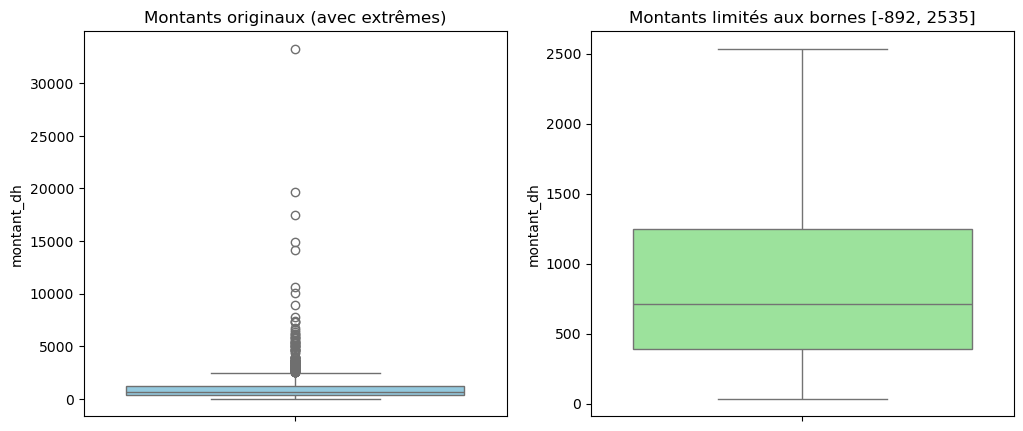

In [45]:
# Q17 : Comparaison visuelle

# Option 1 : Conserver les montants extrêmes (ce que nous avons déjà vu)
# Option 2 : Limiter (capping) les montants aux bornes
X_train_capped = X_train.copy()
X_train_capped['montant_dh'] = X_train_capped['montant_dh'].clip(lower=borne_sous, upper=borne_au_dessus)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=X_train['montant_dh'], ax=axes[0], color='skyblue')
axes[0].set_title('Montants originaux (avec extrêmes)')
sns.boxplot(y=X_train_capped['montant_dh'], ax=axes[1], color='lightgreen')
axes[1].set_title(f'Montants limités aux bornes [{borne_sous:.0f}, {borne_au_dessus:.0f}]')
plt.show()

###  Justification : On limite les valeurs si l'on pense que les extrêmes sont des erreurs ou vont fausser le modèle. On les conserve si l'on pense qu'ils portent une information importante (par exemple, pour détecter la fraude, les montants inhabituels sont un signal)

#### 18_Pour montant_dh, appliquez séparément MinMaxScaler, StandardScaler et RobustScaler. Ajustez chaque méthode sur le groupe de référence, puis transformez le groupe de vérification.

In [55]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
# 1. MinMaxScaler
mms = MinMaxScaler()
mms.fit(X_train[['montant_dh']])
X_train_mms = mms.transform(X_train[['montant_dh']])
X_test_mms = mms.transform(X_test[['montant_dh']])
print("MinMaxScaler (train) -> OK :", X_train_mms[:5].flatten())

# 2. StandardScaler
ss = StandardScaler()
ss.fit(X_train[['montant_dh']])
X_train_ss = ss.transform(X_train[['montant_dh']])
X_test_ss = ss.transform(X_test[['montant_dh']])
print("StandardScaler (train) -> OK :", X_train_ss[:5].flatten())

# 3. RobustScaler
rs = RobustScaler()
rs.fit(X_train[['montant_dh']])
X_train_rs = rs.transform(X_train[['montant_dh']])
X_test_rs = rs.transform(X_test[['montant_dh']])
print("RobustScaler (train) -> OK :", X_train_rs[:5].flatten())

MinMaxScaler (train) -> OK : [0.0115242  0.01493767 0.01327906 0.07464832 0.01077852]
StandardScaler (train) -> OK : [-0.45360714 -0.3696258  -0.41043238  1.09943348 -0.47195308]
RobustScaler (train) -> OK : [-0.33994625 -0.20749724 -0.27185429  2.10939182 -0.36888008]


#### 19-Choisissez trois montants habituels et un montant très élevé. Présentez leurs valeurs avant et après chaque transformation dans un tableau. Quelle méthode est la plus perturbée par les montants extrêmes ?

In [58]:
# Q19 : Tableau comparatif pour 3 montants habituels + 1 montant extrême
# Sélection de 3 valeurs courantes (ex: quantiles) et 1 valeur extrême (ex: max)
m_habituels = np.percentile(X_train['montant_dh'].dropna(), [25, 50, 75])
m_extreme = X_train['montant_dh'].max()

exemples = np.append(m_habituels, m_extreme).reshape(-1, 1)

df_comp = pd.DataFrame({
    'Montant original': exemples.flatten(),
    'MinMaxScaler': mms.transform(exemples).flatten(),
    'StandardScaler': ss.transform(exemples).flatten(),
    'RobustScaler': rs.transform(exemples).flatten()
})

print(df_comp)

   Montant original  MinMaxScaler  StandardScaler  RobustScaler
0          393.0950      0.010729       -0.473170     -0.370800
1          710.7900      0.020285       -0.238059      0.000000
2         1249.8775      0.036501        0.160895      0.629200
3        33281.2300      1.000000       23.865830     38.014829


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


#### D'après le  tableau, les trois montants normaux (393.09, 710.79 et 1249.88 DH) se retrouvent complètement tassés entre 0.010 et 0.036 avec le MinMaxScaler, alors que le montant extrême (33281.23 DH) prend directement 1.000.En conclusion :Le MinMaxScaler est clairement le plus sensible aux outliers. La présence d'une valeur géante pousse le $X_{max}$ vers le haut, ce qui écrase toutes les transactions habituelles et fait perdre au modèle la visibilité sur les variations normales. De son côté, le RobustScaler gère bien mieux la situation et garde une échelle stable. 

## Q20 : Tracé des 3 histogrammes des montants transformés (sur X_train)

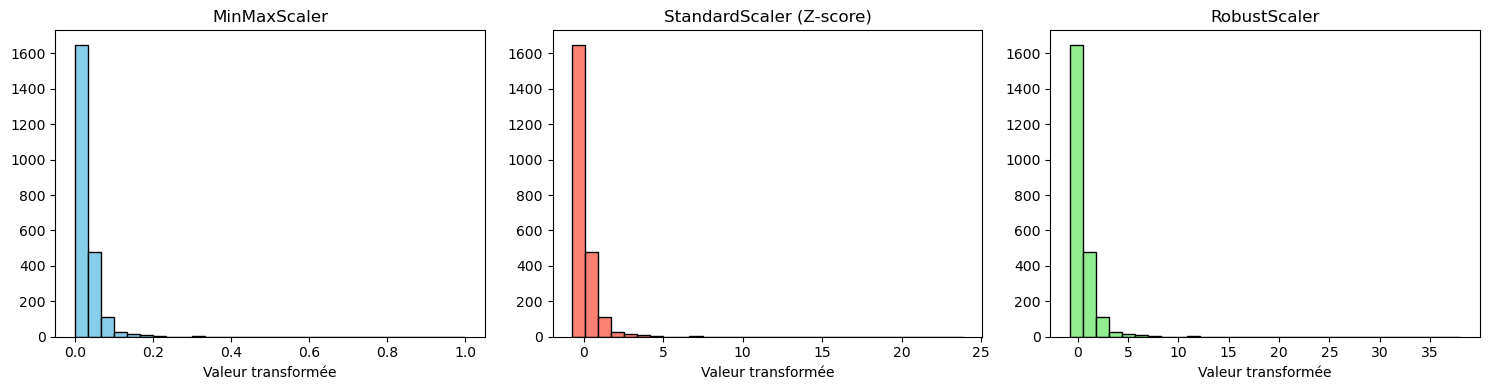

In [62]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. MinMaxScaler
axes[0].hist(X_train_mms, bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('MinMaxScaler')
axes[0].set_xlabel('Valeur transformée')

# 2. StandardScaler (Z-score)
axes[1].hist(X_train_ss, bins=30, color='salmon', edgecolor='black')
axes[1].set_title('StandardScaler (Z-score)')
axes[1].set_xlabel('Valeur transformée')

# 3. RobustScaler
axes[2].hist(X_train_rs, bins=30, color='lightgreen', edgecolor='black')
axes[2].set_title('RobustScaler')
axes[2].set_xlabel('Valeur transformée')

plt.tight_layout()
plt.show()

#### 21-Une nouvelle transaction peut dépasser le maximum du groupe de référence. Avec Min-Max, sa valeur transformée peut-elle dépasser 1 ? Vérifiez avec un petit exemple numérique et expliquez.

In [64]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Exemple numérique simple
train_data = pd.DataFrame({'montant_dh': [150, 200, 550, 1000]})  # Max = 1000

# 1. Fit du scaler sur le groupe de référence
scaler = MinMaxScaler()
scaler.fit(train_data[['montant_dh']])

# 2. Nouvelle transaction supérieure au max de train (ex: 1500 DH)
nouvelle_transaction = pd.DataFrame({'montant_dh': [1500]})

# 3. Transform de la nouvelle transaction
valeur_transformee = scaler.transform(nouvelle_transaction[['montant_dh']])

print(f"Montant max dans train : {train_data['montant_dh'].max()} DH")
print(f"Nouveau montant : {nouvelle_transaction['montant_dh'].values[0]} DH")
print(f"Valeur transformée : {valeur_transformee[0][0]}")

Montant max dans train : 1000 DH
Nouveau montant : 1500 DH
Valeur transformée : 1.588235294117647


In [65]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Données de référence (exemple)
X_ex = np.array([[100], [500], [1000]])

# 2. Fit sur l'exemple
mms_ex = MinMaxScaler()
mms_ex.fit(X_ex)

# 3. Nouvelle transaction dépassant le max (1500 DH)
X_nouveau = np.array([[1500]])
X_nouveau_scaled = mms_ex.transform(X_nouveau)

print(f"Montant initial : {X_nouveau[0][0]} DH")
print(f"Montant transformé : {X_nouveau_scaled[0][0]}")

Montant initial : 1500 DH
Montant transformé : 1.5555555555555556


# Partie 4 — Préparer des classes déséquilibrées

#### 22_Dans le groupe de référence, comptez les lignes de chaque classe (fraude = 0 et fraude = 1). Calculez le rapport entre les deux classes.

In [71]:
# Q22 : Comptage des classes dans le groupe de référence (y_train)
comptage = y_train.value_counts()

nb_normales = comptage.get(0, 0)
nb_fraudes = comptage.get(1, 0)

print(f"Transactions normales (fraude = 0) : {nb_normales}")
print(f"Transactions frauduleuses (fraude = 1) : {nb_fraudes}")

# Calcul du rapport entre les deux classes
if nb_fraudes > 0:
    rapport = nb_normales / nb_fraudes
    print(f"Rapport (Normales / Fraudes) : {rapport:.2f} : 1")
    print(f"Pourcentage de fraudes : {(nb_fraudes / (nb_normales + nb_fraudes)) * 100:.2f}%")
else:
    print("Aucune fraude détectée dans le groupe de référence.")

Transactions normales (fraude = 0) : 2194
Transactions frauduleuses (fraude = 1) : 206
Rapport (Normales / Fraudes) : 10.65 : 1
Pourcentage de fraudes : 8.58%


#### 23-Appliquez RandomOverSampler uniquement au groupe de référence. Notez le nombre de lignes de chaque classe avant et après. Les nouvelles lignes sont-elles des copies de lignes existantes ?

In [74]:
from imblearn.over_sampling import RandomOverSampler

# 1. Vérification avant l'over-sampling
print("--- AVANT RANDOM OVERSAMPLING ---")
print(y_train.value_counts())

# 2. Initialisation et application du RandomOverSampler sur le train uniquement
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# 3. Vérification après l'over-sampling
print("\n--- APRES RANDOM OVERSAMPLING ---")
print(pd.Series(y_train_resampled).value_counts())

--- AVANT RANDOM OVERSAMPLING ---
fraude
0    2194
1     206
Name: count, dtype: int64

--- APRES RANDOM OVERSAMPLING ---
fraude
0    2194
1    2194
Name: count, dtype: int64


#### 24_Reprenez le groupe de référence initial et appliquez RandomUnderSampler. Comptez les lignes conservées et supprimées. Quel est le risque de cette méthode ?

In [77]:
from imblearn.under_sampling import RandomUnderSampler

# 1. Nombre de lignes avant under-sampling
print("--- AVANT RANDOM UNDERSAMPLING ---")
print(y_train.value_counts())

# 2. Initialisation et application du RandomUnderSampler sur le train uniquement
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

# 3. Nombre de lignes après under-sampling
print("\n--- APRES RANDOM UNDERSAMPLING ---")
print(pd.Series(y_train_under).value_counts())

# Calcul des lignes conservées et supprimées
nb_initial = len(y_train)
nb_apres = len(y_train_under)
nb_supprimees = nb_initial - nb_apres

print(f"\nTotal lignes initiales : {nb_initial}")
print(f"Total lignes conservées après sous-échantillonnage : {nb_apres}")
print(f"Total lignes supprimées (perdues) : {nb_supprimees}")

--- AVANT RANDOM UNDERSAMPLING ---
fraude
0    2194
1     206
Name: count, dtype: int64

--- APRES RANDOM UNDERSAMPLING ---
fraude
0    206
1    206
Name: count, dtype: int64

Total lignes initiales : 2400
Total lignes conservées après sous-échantillonnage : 412
Total lignes supprimées (perdues) : 1988


#### 25-Sur un petit exemple à deux variables numériques, illustrez SMOTE : comparez une valeur réelle et une valeur synthétique construite entre deux observations de la classe minoritaire. Expliquez pourquoi cette méthode ne fait pas une simple copie.

In [80]:

from imblearn.over_sampling import SMOTE

# 1. Petit exemple avec 2 variables numériques et un fort déséquilibre
# Classe minoritaire (1) a très peu d'exemples
X_exemple = np.array([
    [1.0, 2.0],  # Obs 1 (Minoritaire)
    [2.0, 3.0],  # Obs 2 (Minoritaire)
    [10.0, 10.0], # Majoritaire
    [10.5, 11.0], # Majoritaire
    [11.0, 10.5]  # Majoritaire
])
y_exemple = np.array([1, 1, 0, 0, 0])

print("--- AVANT SMOTE ---")
print(pd.DataFrame(X_exemple, columns=['Var1', 'Var2']).assign(Classe=y_exemple))

# 2. Application de SMOTE
smote = SMOTE(k_neighbors=1, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_exemple, y_exemple)

print("\n--- APRES SMOTE (Affichage des nouvelles lignes synthétiques) ---")
df_resampled = pd.DataFrame(X_resampled, columns=['Var1', 'Var2'])
df_resampled['Classe'] = y_resampled
print(df_resampled)

--- AVANT SMOTE ---
   Var1  Var2  Classe
0   1.0   2.0       1
1   2.0   3.0       1
2  10.0  10.0       0
3  10.5  11.0       0
4  11.0  10.5       0

--- APRES SMOTE (Affichage des nouvelles lignes synthétiques) ---
        Var1       Var2  Classe
0   1.000000   2.000000       1
1   2.000000   3.000000       1
2  10.000000  10.000000       0
3  10.500000  11.000000       0
4  11.000000  10.500000       0
5   1.796543   2.796543       1


#### Contrairement au RandomOverSampler qui se contente de dupliquer bêtement les lignes, SMOTE fabrique de vraies nouvelles données inédites Par exemple, le point (1.80, 2.80) qu'on vient de générer n'existait pas dans le tableau de départ : il a été calculé pile entre deux observations existantes. Ça évite le simple copier-coller et ça donne de la variété pour protéger le modèle contre le surapprentissage (overfitting).

#### 26-Pourquoi faut-il faire attention lorsque SMOTE est appliqué à des catégories codées en one-hot ? Nommez une méthode conçue pour les données mêlant nombres et catégories.

### Pourquoi faut-il faire attention lorsque SMOTE est appliqué à des catégories codées en one-hot : Il faut faire attention car SMOTE fonctionne par interpolation. Si on l'applique sur des variables catégorielles codées en one-hot (sous forme de 0 et de 1), le mélange de deux catégories peut produire des valeurs décimales comme 0,4, ce qui ne correspond à aucune vraie catégorie et rend les exemples synthétiques irréalistes                    Méthode conçue pour les données mêlant nombres et catégories :                                                                                            L'alternative adaptée pour les données mixtes est la méthode SMOTENC.

In [85]:
from imblearn.over_sampling import SMOTENC

#### 27-Présentez dans un tableau les effectifs des classes avant rééquilibrage, après suréchantillonnage et après sous-échantillonnage. Le groupe de vérification doit-il changer ? Justifiez.

In [88]:

from sklearn.impute import SimpleImputer

#  Imputation des valeurs manquantes (NaN) car SMOTENC ne les accepte pas nativement
# On traite séparément les colonnes numériques et catégorielles pour éviter les erreurs
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

if num_cols:
    num_imputer = SimpleImputer(strategy='median')
    X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])

if cat_cols:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])

#  Identification automatique des indices des colonnes catégorielles
cat_indices = [X_train.columns.get_loc(col) for col in cat_cols]

#  Application de la méthode SMOTENC pour le suréchantillonnage des données mixtes
smotenc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(X_train, y_train)

#  Création du tableau comparatif des effectifs avant et après rééquilibrage
tableau_effectifs = pd.DataFrame({
    "Avant rééquilibrage": y_train.value_counts(),
    "Après suréchantillonnage": y_train_smotenc.value_counts(),
    "Après sous-échantillonnage": y_train_under.value_counts()
}).T

#  Ajout de la colonne du total et affichage du résultat final
tableau_effectifs["Total"] = tableau_effectifs.sum(axis=1)
print(tableau_effectifs)

fraude                         0     1  Total
Avant rééquilibrage         2194   206   2400
Après suréchantillonnage    2194  2194   4388
Après sous-échantillonnage   206   206    412


# Partie 5 — Vérifier et enregistrer les données préparées

#### 28-Créez une version finale de ColumnTransformer : médiane et RobustScaler pour les nombres, modalité fréquente et OneHotEncoder(handle_unknown="ignore") pour les catégories.

In [96]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
# 1. Pipeline de prétraitement pour les variables numériques :
# - Imputation des valeurs manquantes par la médiane
# - Normalisation robuste face aux valeurs aberrantes (RobustScaler)
numeric_transformer = Pipeline(steps=[
    ('imputer_median', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# 2. Pipeline de prétraitement pour les variables catégorielles :
# - Imputation par la modalité la plus fréquente (most_frequent)
# - Encodage One-Hot avec gestion des catégories inconnues (handle_unknown='ignore')
categorical_transformer = Pipeline(steps=[
    ('imputer_freq', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. Assemblage des deux pipelines dans un unique ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

print("Le ColumnTransformer a été configuré avec succès pour toutes les variables.")

Le ColumnTransformer a été configuré avec succès pour toutes les variables.


#### 29-Calculez les paramètres du transformateur final sur le groupe de référence uniquement. Appliquez ensuite ce même transformateur aux deux groupes. Vérifiez le nombre de colonnes et l’absence de valeurs manquantes dans les résultats.

In [99]:
# 1. Ajuster (fit) et transformer uniquement sur le groupe de référence (X_train)
X_train_processed = preprocessor.fit_transform(X_train)

# 2. Appliquer (transform) le même transformateur sur le groupe de test (X_test)
X_test_processed = preprocessor.transform(X_test)

# 3. Vérification du nombre de colonnes et de l'absence de valeurs manquantes

print("--- Vérification des résultats ---")
print("Dimensions de X_train après transformation :", X_train_processed.shape)
print("Dimensions de X_test après transformation :", X_test_processed.shape)

# Compter le nombre total de valeurs NaN (doit être égal à 0)
print("Nombre de valeurs NaN dans X_train_processed :", np.isnan(X_train_processed).sum())
print("Nombre de valeurs NaN dans X_test_processed :", np.isnan(X_test_processed).sum())

--- Vérification des résultats ---
Dimensions de X_train après transformation : (2400, 3191)
Dimensions de X_test après transformation : (600, 3191)
Nombre de valeurs NaN dans X_train_processed : 0
Nombre de valeurs NaN dans X_test_processed : 0


#### 30-Simulez une nouvelle catégorie de canal inconnue du groupe de référence. Vérifiez que OneHotEn- coder peut transformer cette ligne sans erreur. Expliquez le rôle de handle_unknown="ignore".

In [102]:
# Simulation d'une nouvelle catégorie de canal absente du jeu d'entraînement
ligne_test = X_test.iloc[[0]].copy()
ligne_test[cat_cols[0]] = "Nouveau_Canal_Test"

# Transformation avec le preprocessor déjà entraîné
ligne_trans = preprocessor.transform(ligne_test)

print("Transformation réussie sans erreur. Dimensions :", ligne_trans.shape)

Transformation réussie sans erreur. Dimensions : (1, 3191)


### Rôle de handle_unknown="ignore" : Lorsqu'une nouvelle modalité (catégorie) apparaît dans les données de test ou en production alors qu'elle n'était pas présente dans le jeu d'entraînement (X_train) , l'encodeur OneHotEncoder génère normalement une erreur. L'option handle_unknown="ignore" permet d'éviter ce blocage : l'encodeur ignore simplement cette catégorie inconnue et met des zéros (0) dans toutes les colonnes encodées correspondantes, ce qui rend le pipeline plus robuste

#### 31-Enregistrez le transformateur préparé avec joblib, puis rechargez-le. Vérifiez qu’il donne les mêmes valeurs pour un petit échantillon, sans recalculer les médianes ni les échelles.

In [106]:
import joblib
import numpy as np

# 1. Enregistrer le transformateur (preprocessor) dans un fichier
joblib.dump(preprocessor, 'preprocesseur_fraude.pkl')

# 2. Recharger le transformateur depuis le fichier
preprocessor_charge = joblib.load('preprocesseur_fraude.pkl')

# 3. Prendre un petit échantillon pour tester (les 5 premières lignes de X_test)
echantillon = X_test.iloc[:5]

# 4. Appliquer le transformateur d'origine et le transformateur rechargé
res_avant = preprocessor.transform(echantillon)
res_apres = preprocessor_charge.transform(echantillon)

# 5. Vérification que les résultats sont identiques (sans recalculer)
sont_identiques = np.allclose(res_avant, res_apres)

print("--- Vérification de la sauvegarde / rechargement ---")
print("Dimensions de l'échantillon transformé :", res_avant.shape)
print("Les transformateurs donnent-ils des résultats identiques ? :", sont_identiques)

--- Vérification de la sauvegarde / rechargement ---
Dimensions de l'échantillon transformé : (5, 3191)
Les transformateurs donnent-ils des résultats identiques ? : True
